> ### 이 노트북 읽는 법
> 이 파일은 `RecSys_NCF.ipynb`에 **파이썬 초보자용 해설**을 덧붙인 버전입니다.
> - 원본의 셀(설명·코드·실행 결과)은 **그대로** 두었습니다.
> - 번호가 붙은 코드 셀 **바로 아래**마다 `📘 셀 N 해설` 칸을 추가했습니다. 맨 앞 **Base setting 부분(셀 1 ~ 4)은 해설을 생략**했고, 본문인 셀 5 ~ 15를 설명합니다.
> - 해설은 **한 줄 요약 → 코드 뜯어보기 → 출력 해석** 순서입니다. 정의만 하는 셀은 출력이 없으므로 코드 설명 위주입니다.
>
> **이 노트북의 큰 흐름**
> 1. 영화 평점 데이터(MovieLens)를 준비한다 → 2. 사용자와 영화를 각각 숫자 32개(벡터)로 나타내고, 둘을 신경망에 넣어 **평점을 예측**하는 모델을 만든다 → 3. 예측 평점이 실제 평점에 가까워지도록 학습한다 → 4. 평점 오차(**RMSE**)와 추천 품질(**Precision@k, Recall@k**)로 평가한다.
>
> **Base setting에서 만들어 두고 뒤에서 계속 쓰는 것들**
> - `df` : 평점 표. 열은 `userId`, `movieId`, `rating`, `timestamp`. 평점 **100,836건**, 사용자 **610명**, 영화 **9,724편**
> - `device` : 계산을 실행할 장치. 출력이 `cuda`이므로 GPU를 사용합니다.
> - `torch`, `nn` : PyTorch 도구 / `np`, `pd` : numpy, pandas / `plt` : 그래프 도구
> - `model_selection`, `preprocessing` : scikit-learn의 데이터 나누기·전처리 도구
> - `Dataset`, `DataLoader` : 데이터를 묶음 단위로 꺼내 주는 PyTorch 도구
>
> **미리 알아 둘 용어**
> - **협업 필터링(Collaborative Filtering)** : 사용자들의 평점 기록만으로 "이 사람이 이 영화에 몇 점을 줄지"를 예측하는 방법
> - **임베딩(embedding)** : 사용자나 영화 하나를 **숫자 여러 개(벡터)** 로 나타낸 것. 학습을 통해 값이 정해집니다. **latent vector(잠재 벡터)** 라고도 부릅니다.
> - **NCF(Neural Collaborative Filtering)** : 사용자 벡터와 영화 벡터를 **신경망**에 넣어 점수를 예측하는 모델
> - **explicit feedback(명시적 피드백)** : 사용자가 직접 매긴 **평점**. 이 노트북은 평점 숫자를 맞히는 문제를 풉니다.
> - **loss(손실)** : 예측이 정답과 얼마나 다른지를 나타내는 숫자 / **에폭(epoch)** : 학습 데이터 전체를 한 바퀴 도는 것

# Base setting

In [2]:
# 1
!pip install torch
!pip install torch-geometric

In [3]:
# 2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch_geometric.data import download_url, extract_zip

from sklearn import model_selection, metrics, preprocessing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

import random
from tqdm.notebook import tqdm
import math
from collections import defaultdict
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

In [4]:
# 3
url = 'https://files.grouplens.org/datasets/movielens/ml-latest-small.zip'
extract_zip(download_url(url, '.'), '.')

ratings_path = './ml-latest-small/ratings.csv'
# ratings_path = '/content/ratings.csv'
df = pd.read_csv(ratings_path)

print(len(df)) # number of data
print(df['userId'].nunique()) # number of users
print(df['movieId'].nunique()) # number of movies

100836
610
9724


Using existing file ml-latest-small.zip
Extracting .\ml-latest-small.zip


In [5]:
# 4
# need to fix
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# Neural Collaborative filtering

## 1. Data_preprocessing

In [6]:
# 5
# Generate Dataloader object (used as input data for model)
class MovieLens:
  def __init__(self, users, movies, ratings):
    self.users = users
    self.movies = movies
    self.ratings = ratings

  def __len__(self):
    return len(self.users)

  def __getitem__(self,item):
    '''
    item = randomly selected indexes for (user,item) pairs
    '''
    users = self.users[item]
    movies = self.movies[item]
    ratings = self.ratings[item]
    return {'users': torch.tensor(users, dtype = torch.long).to(device),
            'movies': torch.tensor(movies, dtype = torch.long).to(device),
            'ratings': torch.tensor(ratings, dtype=torch.long).to(device)}

### 📘 셀 5 해설
**한 줄 요약:** 평점 데이터를 PyTorch가 **하나씩 꺼내 쓸 수 있는 형태**로 포장하는 클래스 `MovieLens`를 만듭니다.

PyTorch의 `DataLoader`는 데이터 묶음을 만들 때 "전체가 몇 개인가?"와 "`i`번째를 달라"를 물어봅니다. 그 두 질문에 답하는 방법을 정해 두는 것이 Dataset 클래스입니다.

| 함수 | 역할 |
|---|---|
| `__init__(self, users, movies, ratings)` | 사용자 번호·영화 번호·평점 배열을 받아 **보관** |
| `__len__(self)` | 데이터 개수를 돌려줌 (`len(dataset)`을 쓸 때 실행됨) |
| `__getitem__(self, item)` | `item`번째 데이터를 돌려줌 (`dataset[3]`처럼 쓸 때 실행됨) |

- 앞뒤에 밑줄 두 개가 붙은 함수는 파이썬이 **정해진 상황에서 자동으로 부르는** 특별한 함수입니다.
- `__getitem__`은 `{'users': ..., 'movies': ..., 'ratings': ...}` 형태의 **사전(dictionary)** 을 돌려줍니다. 이름표가 붙어 있어 뒤에서 `data['users']`처럼 꺼내 쓰기 편합니다.
- `torch.tensor(users, dtype=torch.long)` : 번호를 **정수 텐서**로 만듭니다. 임베딩 표에서 "몇 번째 줄"을 찾는 데 쓰이므로 정수여야 합니다.
- `.to(device)` : GPU로 옮깁니다.

> **주의할 점:** 평점도 `dtype=torch.long`(정수)으로 바꾸고 있습니다. MovieLens 평점은 0.5 단위(3.5, 4.5 등)인데, 정수로 바꾸면 **소수점 아래가 버려집니다**(3.5 → 3, 0.5 → 0). 따라서 이 노트북의 모델은 소수점이 잘린 평점을 정답으로 학습하고 평가합니다. 평점을 그대로 쓰려면 `torch.float`으로 바꿔야 합니다.

In [7]:
# 6
# convert actual index for user and items as consecutive integer
lbl_user = preprocessing.LabelEncoder()
lbl_movie = preprocessing.LabelEncoder()

df.userId = lbl_user.fit_transform(df.userId.values)
df.movieId = lbl_movie.fit_transform(df.movieId.values)

# devide original dataframe into train, test dataframe (9:1)
df_train, df_test = model_selection.train_test_split(df, test_size=0.1, random_state=42, stratify=df.rating.values)

train_dataset = MovieLens(users = df_train.userId.values, movies = df_train.movieId.values, ratings = df_train.rating.values)
test_dataset = MovieLens(users = df_test.userId.values, movies = df_test.movieId.values, ratings = df_test.rating.values)

print(len(train_dataset))
print(len(test_dataset))

90752
10084


### 📘 셀 6 해설
**한 줄 요약:** 사용자·영화 번호를 **0부터 시작하는 연속된 번호**로 바꾸고, 데이터를 **학습 90% / 테스트 10%** 로 나눕니다.

**① 번호 다시 매기기**
- `preprocessing.LabelEncoder()` : 값들을 0, 1, 2, …로 바꿔 주는 도구
- `lbl_user.fit_transform(df.userId.values)` : 서로 다른 값을 찾고(`fit`) 새 번호로 변환(`transform`)합니다.
- 원래 `movieId`는 중간이 많이 비어 있고 최댓값이 19만이 넘습니다. 임베딩 표의 줄 번호로 쓰려면 **0 ~ 9723처럼 빈틈없는 번호**여야 합니다.

**② 데이터 나누기**
- `model_selection.train_test_split(df, test_size=0.1, random_state=42, stratify=df.rating.values)`
  - `test_size=0.1` : 10%를 테스트용으로
  - `random_state=42` : 난수를 고정해 **다시 실행해도 같게** 나뉘도록 함
  - `stratify=df.rating.values` : 학습·테스트 양쪽의 **평점 분포가 같도록** 나눕니다. 예를 들어 5점짜리가 전체의 13%라면 양쪽 모두 13%가 됩니다.

**③ Dataset 만들기**
- `MovieLens(users=df_train.userId.values, ...)` : 셀 5의 클래스에 학습용·테스트용 데이터를 각각 넣습니다. `.values`는 표의 열을 numpy 배열로 꺼냅니다.

**출력 해석:** 학습 `90752`건, 테스트 `10084`건. 합치면 100,836건입니다. `len(train_dataset)`이 동작하는 것은 셀 5에서 `__len__`을 만들어 두었기 때문입니다.

## 2. Model setting

In [8]:
# 7
### Embedding layer + NCF layer
# 2-layer(including output layer)

# hidden layer + active layer(RELU) + output
# latent vector dim: 32
# input dim: 64

class Neural_Collaborative_Filtering(nn.Module):
  def __init__(self, n_users, n_movies):
    '''
    n_users = # of users
    n_movies = # of movies
    '''
    super().__init__()
    # convert all users and items into 32-dim learnable latent factors(vectors)
    self.user_embedding = nn.Embedding(n_users, 32)
    self.movie_embedding = nn.Embedding(n_movies, 32)

    # Neural network for rating prediction
    self.fc1 = nn.Linear(64,32) # 64 = user_i embedding + movie_j embedding
    self.relu = nn.ReLU()
    self.fc2= nn.Linear(32,1)

  def forward(self, users, movies, ratings = None):
    user_embedding = self.user_embedding(users)
    movie_embedding = self.movie_embedding(movies)
    input_embedding = torch.cat([user_embedding, movie_embedding], dim = 1)

    hidden_feature = self.fc1(input_embedding)
    hidden_feature = self.relu(hidden_feature)

    output = self.fc2(hidden_feature) # output is prediction

    return output

### 📘 셀 7 해설
**한 줄 요약:** **NCF 모델**의 설계도입니다. 사용자 벡터와 영화 벡터를 이어 붙여 작은 신경망에 넣고, **예측 평점 1개**를 내놓습니다.

**부품 (`__init__`)**
- `self.user_embedding = nn.Embedding(n_users, 32)` : **사용자 610명 × 숫자 32개**짜리 표. 사용자 번호를 넣으면 그 줄의 벡터를 꺼내 줍니다.
- `self.movie_embedding = nn.Embedding(n_movies, 32)` : **영화 9,724편 × 숫자 32개**짜리 표
- `self.fc1 = nn.Linear(64, 32)` : 64개 → 32개 / `self.relu = nn.ReLU()` : 음수를 0으로 바꾸는 활성화 함수 / `self.fc2 = nn.Linear(32, 1)` : 32개 → 1개
- `super().__init__()` : 물려받은 `nn.Module`의 준비 작업을 먼저 실행하는 줄로, 모델을 만들 때 항상 씁니다.

임베딩 표의 값은 처음에는 무작위이고, **학습하면서 고쳐집니다.** 학습이 끝나면 취향이 비슷한 사용자끼리, 성격이 비슷한 영화끼리 벡터가 비슷해집니다.

**계산 과정 (`forward`)**

| 코드 | 모양 (묶음 128개 기준) | 의미 |
|---|---|---|
| `self.user_embedding(users)` | `(128, 32)` | 사용자 번호 → 벡터 |
| `self.movie_embedding(movies)` | `(128, 32)` | 영화 번호 → 벡터 |
| `torch.cat([...], dim=1)` | `(128, 64)` | 두 벡터를 **옆으로 이어 붙임** |
| `self.fc1(...)` → `self.relu(...)` | `(128, 32)` | 은닉층 |
| `self.fc2(...)` | `(128, 1)` | **예측 평점** |

- `forward`의 인자 `ratings=None`은 받기만 하고 사용하지 않습니다.

**행렬 분해(Matrix Factorization)와의 차이:** 전통적인 방법은 사용자 벡터와 영화 벡터를 **내적**(같은 자리끼리 곱해 더함)해서 점수를 냅니다. NCF는 그 자리에 **신경망**을 두어, 두 벡터를 어떻게 조합할지도 데이터로부터 배우게 합니다.

## 3. Training

In [9]:
# 8
# set batch
train_loader = DataLoader(dataset = train_dataset, batch_size=128, shuffle=True, drop_last=False)
test_loader = DataLoader(dataset = test_dataset, batch_size=128, shuffle=True, drop_last = False)

### 📘 셀 8 해설
**한 줄 요약:** 데이터를 **128개씩 묶어서** 꺼내 주는 `DataLoader`를 만듭니다.

- `batch_size=128` : 한 묶음의 크기
- `shuffle=True` : 에폭마다 순서를 섞습니다. 평점 데이터는 시간 순서가 중요하지 않으므로 섞어서 학습합니다.
- `drop_last=False` : 마지막에 128개가 안 되는 묶음이 남아도 버리지 않고 사용합니다.

학습 데이터 90,752건 ÷ 128 = **709묶음**으로 딱 나누어떨어집니다. 한 에폭은 709번의 반복입니다.

`DataLoader`가 꺼내 주는 묶음은 셀 5에서 정한 대로 `{'users': 128개, 'movies': 128개, 'ratings': 128개}` 형태의 사전입니다.

In [10]:
# 9
# model instance generation
model = Neural_Collaborative_Filtering(n_users = len(lbl_user.classes_), n_movies = len(lbl_movie.classes_)).to(device)

# Optimizer, Objective function
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)
loss_func = nn.MSELoss(reduction= 'mean')

### 📘 셀 9 해설
**한 줄 요약:** 모델을 실제로 만들고, 학습에 필요한 **옵티마이저**와 **손실 함수**를 준비합니다.

- `len(lbl_user.classes_)` : 셀 6의 LabelEncoder가 찾은 서로 다른 사용자 수(610). `len(lbl_movie.classes_)`는 영화 수(9,724)입니다.
- `.to(device)` : 모델을 GPU로 옮깁니다.
- `torch.optim.Adam(model.parameters(), lr=0.001)` : 가중치를 고쳐 주는 도구. `lr`(학습률)은 한 번에 고치는 폭입니다.
- `nn.MSELoss(reduction='mean')` : **평균 제곱 오차**. (예측 평점 − 실제 평점)을 제곱해 평균 낸 값입니다. 숫자를 맞히는 문제(회귀)에 쓰는 표준 손실 함수입니다.

이 모델에서 학습되는 값은 약 33만 개이며, 대부분(약 31만 개)이 영화 임베딩 표에 있습니다.

In [11]:
# 10
epochs = 5
total_loss = 0
iter_cnt = 0
all_losses_list = []

model.train()

for epoch in range(1, epochs+1):
  total_loss = 0
  epoch_check = 0
  for i, train_data in enumerate(train_loader):
    '''
    train_data = {'users':[], 'items':[], 'ratings':[]}
    '''
    batch_size = len(train_data['users'])
    prediction = model(train_data['users'], train_data['movies'])
    ground_truth = train_data['ratings'].view(batch_size,-1).to(torch.float32)

    loss = loss_func(prediction, ground_truth)
    total_loss = total_loss + (loss.item() * batch_size)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    iter_cnt = iter_cnt + 1
    epoch_check += batch_size

    if iter_cnt % 100 == 0 and iter_cnt != 0:
      avg_iter_loss = loss.item()
      batch_num = int((iter_cnt/100) % 7) if int((iter_cnt/100) % 7) else 7
      print(f"epoch {epoch} - (batch {batch_num}) loss : {(avg_iter_loss)}")


    if epoch_check % (batch_size * len(train_loader)) == 0 and epoch_check != 0:
      avg_loss = total_loss / epoch_check
      print(f"Epoch {epoch} Avg_loss : {avg_loss}")
      all_losses_list.append(avg_loss)


epoch 1 - (batch 1) loss : 3.5447282791137695
epoch 1 - (batch 2) loss : 1.9766325950622559
epoch 1 - (batch 3) loss : 1.2287323474884033
epoch 1 - (batch 4) loss : 1.2041709423065186
epoch 1 - (batch 5) loss : 1.6206623315811157
epoch 1 - (batch 6) loss : 0.9617823958396912
epoch 1 - (batch 7) loss : 1.0125373601913452
Epoch 1 Avg_loss : 2.2594316261275362
epoch 2 - (batch 1) loss : 0.8843932151794434
epoch 2 - (batch 2) loss : 1.5403287410736084
epoch 2 - (batch 3) loss : 1.093364953994751
epoch 2 - (batch 4) loss : 1.0491746664047241
epoch 2 - (batch 5) loss : 0.8928346037864685
epoch 2 - (batch 6) loss : 1.138991355895996
epoch 2 - (batch 7) loss : 0.7868907451629639
Epoch 2 Avg_loss : 1.0115315242445855
epoch 3 - (batch 1) loss : 1.0013587474822998
epoch 3 - (batch 2) loss : 1.0141606330871582
epoch 3 - (batch 3) loss : 1.1032681465148926
epoch 3 - (batch 4) loss : 0.9735916256904602
epoch 3 - (batch 5) loss : 0.8575401306152344
epoch 3 - (batch 6) loss : 0.8116519451141357
epoch 

### 📘 셀 10 해설
**한 줄 요약:** 모델을 **5 에폭 학습**시키는 반복문입니다.

**학습의 핵심 (묶음마다 실행)**

| 코드 | 의미 |
|---|---|
| `batch_size = len(train_data['users'])` | 이번 묶음의 실제 크기 |
| `prediction = model(train_data['users'], train_data['movies'])` | 예측 평점. 모양 `(128, 1)` |
| `ground_truth = train_data['ratings'].view(batch_size, -1).to(torch.float32)` | 실제 평점. 모양을 `(128,)` → `(128, 1)`로 바꾸고 실수로 변환 |
| `loss = loss_func(prediction, ground_truth)` | 손실(MSE) 계산 |
| `optimizer.zero_grad()` | 이전 묶음의 기울기를 0으로 초기화 |
| `loss.backward()` | 가중치별 기울기 계산 (역전파) |
| `optimizer.step()` | 가중치 수정 |

- `.view(batch_size, -1)` : 모양을 바꿉니다. `-1`은 "나머지는 알아서 맞춰라"는 뜻입니다. 예측과 정답의 **모양을 똑같이 맞추는 것**이 중요합니다. 모양이 `(128, 1)`과 `(128,)`로 다르면 오류 없이 엉뚱한 값이 계산될 수 있습니다.
- `model.train()` : 모델을 학습 모드로 전환합니다(반복문 앞에서 한 번 실행).

**기록용 코드**
- `total_loss = total_loss + (loss.item() * batch_size)` : `loss`는 묶음의 **평균**이므로 묶음 크기를 곱해 **합계**로 만들어 누적합니다. 나중에 전체 개수로 나누면 정확한 에폭 평균이 됩니다.
- `iter_cnt` : 지금까지 처리한 묶음 수 / `epoch_check` : 이번 에폭에서 처리한 데이터 수
- `if iter_cnt % 100 == 0 ...` : 묶음 **100개마다** 현재 손실을 출력합니다(`%`는 나머지). 출력의 `(batch 1)` ~ `(batch 7)`은 한 에폭 안에서 몇 번째 출력인지를 나타내는 번호이지, 실제 묶음 번호가 아닙니다.
- `if epoch_check % (batch_size * len(train_loader)) == 0 ...` : 한 에폭의 데이터를 모두 처리했을 때 **에폭 평균 손실**을 출력하고 `all_losses_list`에 보관합니다.

**출력 해석**
- 에폭 평균 손실: `2.259 → 1.012 → 0.921 → 0.866 → 0.825` 로 매 에폭 감소
- 첫 에폭에서 크게 줄고(처음 100묶음째 3.54 → 700묶음째 1.01) 그 뒤로는 천천히 줄어듭니다.
- 100묶음마다 찍힌 값은 0.64 ~ 1.62 사이에서 **들쭉날쭉**합니다. 묶음 하나(128건)의 손실은 어떤 데이터가 뽑혔는지에 따라 달라지기 때문이며 정상입니다. 추세는 에폭 평균으로 봐야 합니다.
- MSE 0.82는 평균적으로 약 0.9점(√0.82) 정도 틀린다는 뜻입니다.

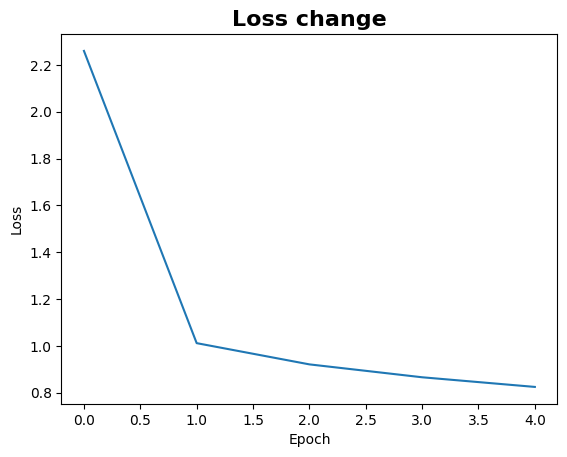

In [12]:
# 11
# Show Loss change
plt.figure()

title_font = {
    'fontsize': 16,
    'fontweight': 'bold'
}

plt.title('Loss change',fontdict=title_font)
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.plot(all_losses_list)
plt.show()

### 📘 셀 11 해설
**한 줄 요약:** 에폭별 평균 손실을 **그래프**로 그립니다.

- `plt.figure()` : 새 그래프를 준비
- `title_font = {...}` : 제목의 글자 크기와 굵기를 사전으로 정해 둡니다.
- `plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)` : 제목과 가로축·세로축 이름
- `plt.plot(all_losses_list)` : 셀 10에서 모아 둔 값 5개를 선으로 잇습니다. 가로축 값을 따로 주지 않았으므로 **0, 1, 2, 3, 4**가 됩니다(0이 첫 번째 에폭).
- `plt.show()` : 화면에 표시

**출력 해석:** 첫 에폭에서 두 번째 에폭 사이에 2.26 → 1.01로 **급격히 떨어지고**, 그 뒤로는 완만하게 내려갑니다. 아직 조금씩 줄고 있으므로 에폭을 늘리면 학습 손실은 더 내려갈 여지가 있습니다.

## 4. Evaluation

### RMSE

In [13]:
# 12
from sklearn.metrics import mean_squared_error

model_output_list = []
target_rating_list = []

model.eval()

with torch.no_grad():
  for i, batched_data in enumerate(test_loader):
    model_output = model(batched_data['users'],batched_data['movies'])
    model_output_batch = model_output.cpu().numpy().squeeze(axis=1).tolist()
    model_output_list += (model_output_batch)

    target_rating = batched_data['ratings']
    target_rating_batch = target_rating.cpu().numpy().tolist()
    target_rating_list += target_rating_batch

mse = mean_squared_error(target_rating_list, model_output_list)
rms = np.sqrt(mse)
print(f"rms: {rms}")

rms: 0.9490524465538113


### 📘 셀 12 해설
**한 줄 요약:** 테스트 데이터에 대한 예측 평점과 실제 평점의 차이를 **RMSE**로 계산합니다.

- `model.eval()` : 모델을 **평가 모드**로 전환
- `with torch.no_grad():` : 이 블록 안에서는 기울기를 계산하지 않습니다. 평가에는 필요 없으므로 더 빠르고 메모리를 아낍니다.
- `model_output.cpu().numpy().squeeze(axis=1).tolist()` : 왼쪽부터 차례로 읽습니다.
  - `.cpu()` : GPU → CPU로 이동 / `.numpy()` : numpy 배열로 변환
  - `.squeeze(axis=1)` : 모양 `(128, 1)`을 `(128,)`로 / `.tolist()` : 파이썬 리스트로 변환
- `model_output_list += (...)` : 리스트 뒤에 **이어 붙입니다.** 모든 묶음의 예측을 하나의 긴 리스트로 모읍니다.
- `mse = mean_squared_error(target_rating_list, model_output_list)` : 평균 제곱 오차
- `rms = np.sqrt(mse)` : 제곱근을 취해 **RMSE**로 만듭니다. 제곱했던 것을 되돌려 **평점과 같은 단위**로 읽을 수 있게 됩니다.

**출력 해석:** `rms: 0.949`
- 모델의 예측이 실제 평점과 **평균적으로 약 0.95점** 차이 난다는 뜻입니다(5점 만점 기준).
- 학습 데이터에서의 오차(약 0.9점)와 비슷하므로, 학습 데이터만 외운 상태(과적합)는 아닙니다.
- 셀 5에서 설명했듯 여기서의 "실제 평점"은 소수점이 잘린 값입니다.

### Recall@k & Precision@k

In [14]:
# 13
from collections import defaultdict

user_est_true = defaultdict(list)

with torch.no_grad():
  for i, batched_data in enumerate(test_loader):
    users = batched_data['users']
    movies = batched_data['movies']
    ratings = batched_data['ratings']

    model_output = model(batched_data['users'], batched_data["movies"])

    for i in range(len(users)):
      user_id = users[i].item()
      movie_id = movies[i].item()
      pred_rating = model_output[i][0].item()
      true_rating = ratings[i].item()

      user_est_true[user_id].append((pred_rating, true_rating))

### 📘 셀 13 해설
**한 줄 요약:** 테스트 데이터의 예측 결과를 **사용자별로 모읍니다.**

- `user_est_true = defaultdict(list)` : 처음 보는 사용자 번호가 나오면 **자동으로 빈 리스트를 만들어 주는** 사전입니다. 일반 사전은 없는 번호에 `.append`를 하면 오류가 납니다.
- 바깥 반복문 : 테스트 데이터를 묶음 단위로 꺼내 예측합니다.
- 안쪽 반복문 `for i in range(len(users)):` : 묶음 안의 데이터를 하나씩 처리합니다.
  - `users[i].item()` : 텐서에 들어 있는 값 하나를 파이썬 숫자로 꺼냅니다.
  - `model_output[i][0].item()` : `i`번째 예측 평점
  - `user_est_true[user_id].append((pred_rating, true_rating))` : 그 사용자의 리스트에 **(예측 평점, 실제 평점)** 한 쌍을 추가합니다.

결과는 다음과 같은 모양입니다.

```
{ 사용자 0: [(예측 4.2, 실제 5), (예측 3.1, 실제 3), ...],
  사용자 1: [(예측 3.8, 실제 4), ...],
  ... }
```

이 셀은 준비 단계라 출력이 없습니다. 다음 셀에서 이 사전을 사용합니다.

In [15]:
# 14
with torch.no_grad():
  precisions = dict()
  recalls = dict()

  # recall@K
  k= 10
  threshold = 3.5 # relevant item criterion

  for user_id, user_ratings in user_est_true.items():
    user_ratings.sort(key=lambda x: x[0], reverse =True)

    # get the number for real relevant items = denominator of recall@k
    n_real_relevant= sum((true_r >= threshold) for (_, true_r) in user_ratings)

    # k recommended ratings
    recommended_k = user_ratings[:k]

    # get the number of recommented item that is actually relevant with real relevant.
    n_real_relevant_in_top_k = sum((true_r >= threshold) for (est, true_r) in recommended_k)

    # precision@k
    precisions[user_id] = n_real_relevant_in_top_k / 10
    # recall@k
    if n_real_relevant:
      recalls[user_id] = n_real_relevant_in_top_k / n_real_relevant

    else:
      recalls[user_id] = 0


### 📘 셀 14 해설
**한 줄 요약:** 사용자마다 **예측 평점이 높은 10개**를 "추천 목록"으로 보고, **Precision@10**과 **Recall@10**을 계산합니다.

**설정**
- `k = 10` : 추천 개수
- `threshold = 3.5` : 실제 평점이 3.5 이상이면 "**좋아한 영화**"(relevant)로 봅니다. 평점이 정수로 바뀌어 있으므로(셀 5) 실제로는 **4점 이상**이 해당됩니다.

**사용자 한 명에 대한 계산**

| 코드 | 의미 |
|---|---|
| `user_ratings.sort(key=lambda x: x[0], reverse=True)` | **예측 평점이 높은 순**으로 정렬 |
| `n_real_relevant = sum((true_r >= threshold) for (_, true_r) in user_ratings)` | 이 사용자가 실제로 좋아한 영화의 수 |
| `recommended_k = user_ratings[:k]` | 앞에서 10개 = 추천 목록 |
| `n_real_relevant_in_top_k = sum(...)` | 추천 10개 중 실제로 좋아한 영화의 수 |

- `key=lambda x: x[0]` : 정렬 기준을 알려 주는 부분입니다. `lambda x: x[0]`은 "쌍 `x`에서 첫 번째(예측 평점)를 꺼내라"는 **이름 없는 짧은 함수**입니다. `reverse=True`는 큰 것부터 정렬하라는 뜻입니다.
- `sum((true_r >= threshold) for ...)` : 조건이 참이면 1, 거짓이면 0으로 계산되므로 **조건을 만족하는 개수**를 세는 방법입니다.

**두 지표** (둘 다 **높을수록 좋음**)
- `precisions[user_id] = n_real_relevant_in_top_k / 10` : **Precision@10** = 추천한 10개 중 좋아한 영화의 비율
- `recalls[user_id] = n_real_relevant_in_top_k / n_real_relevant` : **Recall@10** = 좋아한 영화 중 추천 10개 안에 들어온 비율
- `if n_real_relevant:` : 좋아한 영화가 하나도 없으면 0으로 나눌 수 없으므로 recall을 0으로 둡니다. 파이썬에서 숫자 0은 거짓, 그 외의 숫자는 참으로 취급됩니다.

> 이 평가는 **테스트 데이터에 들어 있는 영화들 안에서만** 순위를 매깁니다. 사용자 한 명의 테스트 영화는 평균 16편 정도이며, 10편이 안 되는 사용자도 많습니다. 그런 사용자는 추천 목록이 10개가 안 되는데도 10으로 나누므로 precision이 실제보다 낮게 계산됩니다.

In [16]:
# 15
# Precision and recall can then be averaged over all users
print(f"precision @ {k}: {sum(prec for prec in precisions.values()) / len(precisions)}")

print(f"recall @ {k} : {sum(rec for rec in recalls.values()) / len(recalls)}")

precision @ 10: 0.4138333333333328
recall @ 10 : 0.7459710214411714


### 📘 셀 15 해설
**한 줄 요약:** 사용자별로 구한 precision과 recall의 **평균**을 출력합니다.

- `sum(prec for prec in precisions.values()) / len(precisions)` : 사전의 값들을 모두 더해 사용자 수로 나눕니다. `.values()`는 사전에서 값만 꺼냅니다.

**출력 해석**
- `precision @ 10: 0.4138` : 추천 10개 중 평균 약 **4개**가 실제로 좋아한 영화
- `recall @ 10: 0.7460` : 좋아한 영화의 약 **75%** 가 추천 10개 안에 포함됨

**숫자를 읽을 때 주의할 점**
- recall이 높은 큰 이유는 사용자당 테스트 영화가 적기 때문입니다. 테스트 영화가 10편 이하인 사용자는 전부가 추천 목록에 들어가므로 recall이 자동으로 1이 됩니다.
- GCF 실습(`RecSys_GCF`)의 Recall@10은 약 0.06이었지만, 그쪽은 **9,724편 전체**에서 10편을 고르는 문제였습니다. 평가 방식이 달라서 두 숫자를 직접 비교할 수 없습니다.

**전체 실습 정리**
1. 사용자와 영화를 각각 **임베딩 벡터**로 나타내고, 그 값을 학습으로 찾습니다.
2. NCF는 두 벡터를 이어 붙여 **신경망**에 넣어 점수를 예측합니다(내적 대신 신경망 사용).
3. 이 노트북은 **평점 숫자**를 맞히는 회귀 문제로 풀었고, 손실은 **MSE**, 평가는 **RMSE**입니다.
4. 추천 품질은 예측 점수가 높은 순으로 k개를 뽑아 **Precision@k, Recall@k**로 평가합니다.
5. 두 추천 실습의 차이:

| | NCF (이 노트북) | NGCF (GCF 실습) |
|---|---|---|
| 사용하는 정보 | 평점 숫자 (explicit) | 봤는지 여부 (implicit) |
| 모델 | 임베딩 + 신경망 | 임베딩 + 그래프 신경망 |
| 손실 | MSE (점수 맞히기) | BPR (순서 맞히기) |
| 주요 평가 지표 | RMSE | Recall@k, NDCG@k |